# 02. Shortcut stress tests

Notebook 01 found that the TF-IDF baseline scores 0.96 macro F1, but its strongest features are
years, politician names, and platform words. Real articles in this corpus mostly date from 2012 to
2015 and fake articles from 2016 to 2019, and fake articles are about twice as long. A model can
score well by recognizing the source and period instead of the content.

This notebook builds two harder versions of the same test set and checks how much each model's score
drops on them:

1. **Length-matched.** Inside each of 10 length bins, real and fake articles are subsampled to equal
   counts, so article length says nothing about the label.
2. **Masked.** Numbers and years become `xxnum`, capitalized words that do not start a sentence become
   `xxname`, URLs and platform words (video, facebook, panoorin, and similar) are removed, and the text
   is lowercased.

A third version combines both. Every stress set is a subset or a rewrite of the same 451 test
articles from notebook 01, so no training article leaks in.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))
from fakenews_data import (
    LABEL_NAMES, PLATFORM_WORDS,
    bootstrap_macro_f1, build_test_sets, load_splits, mask_shortcuts, masked_copy, word_count,
)

DATA_DIR = REPO_ROOT / "data" / "raw"
RESULTS_DIR = REPO_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"

train_df, val_df, test_df = load_splits(DATA_DIR)
print(f"train {len(train_df)}, val {len(val_df)}, test {len(test_df)}")

train 2103, val 451, test 451


## What masking does

One real and one fake test article, before and after masking (first 300 characters).

In [2]:
for label in [0, 1]:
    example = test_df[test_df["label"] == label]["article"].iloc[0]
    print(f"[{LABEL_NAMES[label]}] original:\n{example[:300]}\n")
    print(f"[{LABEL_NAMES[label]}] masked:\n{mask_shortcuts(example)[:300]}\n")

print("Platform words removed:", ", ".join(PLATFORM_WORDS))

[Real] original:
Lumitaw sa imbestigasyon ng pulisya na ang dalawa ang itinuturong bumaril at nakapatay kay PO2 Jan Gallenero, nakatalaga sa Intelligence Section ng La Carlota Police Station noong nakaraang linggo. Nakasaad sa report ng pulisya na si Aizpuro ay kamag-anak din ng biktima at kasama sa La Carlota Polic

[Real] masked:
lumitaw sa imbestigasyon ng pulisya na ang dalawa ang itinuturong bumaril at nakapatay kay xxname xxnum xxname xxname nakatalaga sa xxname xxname ng xxname xxname xxname xxname noong nakaraang linggo. nakasaad sa report ng pulisya na si xxname ay kamag-anak din ng biktima at kasama sa xxname xxname 

[Fake] original:
Isang magsasaka sa Urdaneta City sa Pangasinan ang pinaulanan ng saksak ng isang umano'y tinderong naingayan sa tambutso ng motorsiklong minamaneho ng biktima. Ayon sa ulat ng GMA News, batay sa imbestigasyon ay kasalukuyan umanong natutulog noon ang suspek na si Rodolfo Mellon nang magising sa main

[Fake] masked:
isang magsasaka sa xxname xxna

## Build the stress test sets

In [3]:
test_sets = build_test_sets(test_df)

summary_rows = []
for name, df in test_sets.items():
    lengths = word_count(df["article"])
    summary_rows.append({
        "test_set": name,
        "articles": len(df),
        "fake_share": df["label"].mean(),
        "median_words_real": lengths[df["label"] == 0].median(),
        "median_words_fake": lengths[df["label"] == 1].median(),
    })
print(pd.DataFrame(summary_rows).round(3).to_string(index=False))

             test_set  articles  fake_share  median_words_real  median_words_fake
             standard       451       0.501               77.0              234.5
       length_matched       202       0.500              181.0              181.0
               masked       451       0.501               79.0              235.5
masked_length_matched       202       0.500              184.0              180.0


## Models

Three cheap models, all trained on the training split only:

- **Length only.** Logistic regression on log word count. It measures how far length alone goes.
- **TF-IDF, original text.** The notebook 01 baseline. On the masked sets it is given masked text,
  which tests how much it relied on the masked cues.
- **TF-IDF, masked text.** The same model trained and tuned on masked text. It shows what can be
  learned once the cues are gone.

In [4]:
def length_features(df):
    return np.log1p(word_count(df["article"])).to_frame("log_words")


def fit_tfidf_logreg(train, val):
    vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    X_train = vectorizer.fit_transform(train["article"])
    X_val = vectorizer.transform(val["article"])

    best_f1, best_C = -1, None
    for C in [0.1, 0.3, 1, 3, 10, 30, 100]:
        model = LogisticRegression(C=C, max_iter=2000).fit(X_train, train["label"])
        f1 = f1_score(val["label"], model.predict(X_val), average="macro")
        if f1 > best_f1:
            best_f1, best_C = f1, C

    model = LogisticRegression(C=best_C, max_iter=2000).fit(X_train, train["label"])
    print(f"best C = {best_C}, val macro F1 = {best_f1:.4f}")
    return vectorizer, model


length_model = LogisticRegression().fit(length_features(train_df), train_df["label"])

print("TF-IDF, original text:")
vec_original, tfidf_original = fit_tfidf_logreg(train_df, val_df)

print("TF-IDF, masked text:")
train_masked, val_masked = masked_copy(train_df), masked_copy(val_df)
vec_masked, tfidf_masked = fit_tfidf_logreg(train_masked, val_masked)

TF-IDF, original text:


best C = 10, val macro F1 = 0.9667
TF-IDF, masked text:


best C = 100, val macro F1 = 0.9424


## Scores

Each score is macro F1 with a 95% bootstrap interval (1,000 resamples of the test articles). A model
that guesses at random scores about 0.50. The masked-text model is only scored on masked sets,
since it never saw unmasked text.

In [5]:
def predict(model_name, df):
    if model_name == "length_only":
        return length_model.predict(length_features(df))
    if model_name == "tfidf_original":
        return tfidf_original.predict(vec_original.transform(df["article"]))
    if model_name == "tfidf_masked":
        return tfidf_masked.predict(vec_masked.transform(df["article"]))


score_rows = []
for model_name in ["length_only", "tfidf_original", "tfidf_masked"]:
    for set_name, df in test_sets.items():
        if model_name == "tfidf_masked" and not set_name.startswith("masked"):
            continue
        y_pred = predict(model_name, df)
        low, high = bootstrap_macro_f1(df["label"], y_pred)
        score_rows.append({
            "model": model_name,
            "test_set": set_name,
            "n": len(df),
            "macro_f1": f1_score(df["label"], y_pred, average="macro"),
            "ci_low": low,
            "ci_high": high,
        })

scores = pd.DataFrame(score_rows)
scores.to_csv(RESULTS_DIR / "metrics_stress_tests_classic.csv", index=False)
print(scores.round(3).to_string(index=False))

         model              test_set   n  macro_f1  ci_low  ci_high
   length_only              standard 451     0.777   0.738    0.818
   length_only        length_matched 202     0.499   0.429    0.566
   length_only                masked 451     0.775   0.735    0.816
   length_only masked_length_matched 202     0.495   0.425    0.561
tfidf_original              standard 451     0.962   0.945    0.980
tfidf_original        length_matched 202     0.941   0.906    0.970
tfidf_original                masked 451     0.913   0.887    0.936
tfidf_original masked_length_matched 202     0.871   0.825    0.915
  tfidf_masked                masked 451     0.945   0.922    0.962
  tfidf_masked masked_length_matched 202     0.911   0.870    0.945


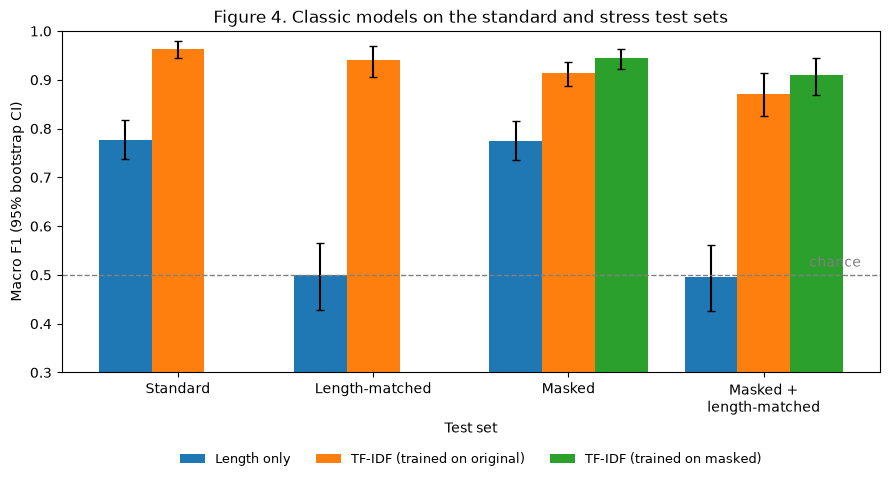

In [6]:
set_order = list(test_sets.keys())
set_labels = ["Standard", "Length-matched", "Masked", "Masked +\nlength-matched"]
model_labels = {
    "length_only": "Length only",
    "tfidf_original": "TF-IDF (trained on original)",
    "tfidf_masked": "TF-IDF (trained on masked)",
}
bar_width = 0.27

fig, ax = plt.subplots(figsize=(9, 5))
for i, (model_name, model_label) in enumerate(model_labels.items()):
    rows = scores[scores["model"] == model_name].set_index("test_set")
    x = [set_order.index(s) + (i - 1) * bar_width for s in rows.index]
    errors = [rows["macro_f1"] - rows["ci_low"], rows["ci_high"] - rows["macro_f1"]]
    ax.bar(x, rows["macro_f1"], width=bar_width, yerr=errors, capsize=3, label=model_label)

ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.text(len(set_order) - 0.5, 0.51, "chance", color="gray", ha="right", va="bottom")
ax.set_xticks(range(len(set_order)), set_labels)
ax.set_ylim(0.3, 1.0)
ax.set_ylabel("Macro F1 (95% bootstrap CI)")
ax.set_xlabel("Test set")
ax.set_title("Figure 4. Classic models on the standard and stress test sets")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=9, frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig4_stress_tests_classic.png", dpi=150)
plt.show()

## What the masked model still uses

If the masked model still scores well, these are the cues left once names, numbers, and platform
words are gone.

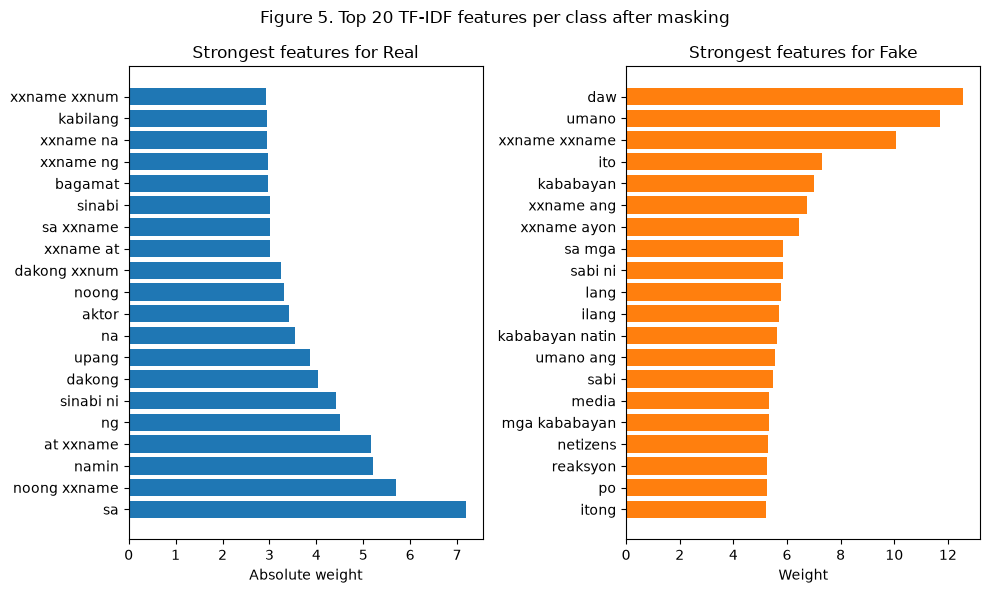

real_feature  real_weight    fake_feature  fake_weight
          sa       -7.185             daw       12.567
noong xxname       -5.691           umano       11.704
       namin       -5.201   xxname xxname       10.045
   at xxname       -5.157             ito        7.303
          ng       -4.494       kababayan        7.009
   sinabi ni       -4.423      xxname ang        6.728
      dakong       -4.037     xxname ayon        6.453
       upang       -3.870          sa mga        5.868
          na       -3.542         sabi ni        5.840
       aktor       -3.426            lang        5.770
       noong       -3.306           ilang        5.693
dakong xxnum       -3.243 kababayan natin        5.642
   xxname at       -3.019       umano ang        5.562
   sa xxname       -3.016            sabi        5.482
      sinabi       -3.009           media        5.343
     bagamat       -2.975   mga kababayan        5.312
   xxname ng       -2.966        netizens        5.305
   xxname 

In [7]:
feature_names = np.array(vec_masked.get_feature_names_out())
weights = tfidf_masked.coef_[0]
top_k = 20
top_fake = np.argsort(weights)[-top_k:]
top_real = np.argsort(weights)[:top_k]

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].barh(feature_names[top_real], -weights[top_real], color="tab:blue")
axes[0].set_title("Strongest features for Real")
axes[0].set_xlabel("Absolute weight")
axes[1].barh(feature_names[top_fake], weights[top_fake], color="tab:orange")
axes[1].set_title("Strongest features for Fake")
axes[1].set_xlabel("Weight")
fig.suptitle("Figure 5. Top 20 TF-IDF features per class after masking")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig5_top_features_masked.png", dpi=150)
plt.show()

masked_features = pd.DataFrame({
    "real_feature": feature_names[top_real],
    "real_weight": weights[top_real].round(3),
    "fake_feature": feature_names[top_fake][::-1],
    "fake_weight": weights[top_fake][::-1].round(3),
})
masked_features.to_csv(RESULTS_DIR / "top_features_tfidf_masked.csv", index=False)
print(masked_features.to_string(index=False))